# Multi-head looped transformer experiments

# My Custom Experiments

In the previous sections I have attempted to re-produce experiments from Gatmiry et al. In the following sections, I will implement several experiments that apply different assumptions and test the theoretical bounds of this paper. These were not written in the original paper.

In [1]:
# Imports and setup

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from experiments_helper import (
    run_experiment_suite,
    compute_loss_dict,
    compute_dist_dict,
    plot_loss_curves,
    plot_parameter_matrices,
    plot_dist_to_identity,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [2]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

Running on device: cuda.


# Multi-head looped transformer sweep

Train only the shared-weight looped transformer on the same Gaussian regression task while sweeping the number of attention heads over [1, 2, 4, 8]. This mirrors the original depth/loop experiment, but now the architecture is allowed to vary in width instead of type. The run uses the same seeds, loop counts, context length, and training setup as the baseline, and stores the resulting histories and test losses for comparison across head counts.

In [ ]:
multihead_seeds = [0, 1, 2]
multihead_loop_counts = [5]
multihead_model_types = ['looped']
multihead_head_counts = [1, 2, 4, 8]
multihead_context_lengths = [N]

20


In [ ]:
# --- Multi-head looped transformer sweep ---

multihead_filename = os.path.join(cur_dir, f'looped_multihead_N{N}_d{d}_histories.pth')
multihead_results_file = os.path.join(cur_dir, f'looped_multihead_N{N}_d{d}_results.pth')

multihead_hist_dict = run_experiment_suite(
    seeds=multihead_seeds,
    n_layers_loops=multihead_loop_counts,
    model_types=multihead_model_types,
    filename=multihead_filename,
    context_lengths=multihead_context_lengths,
    data_modes=[normal_data_mode],
    head_counts=multihead_head_counts,
    freeze_p=True,  # [P-FIX] paper's P = [[0, 0], [0, 1]]
)

multihead_loss_dict = compute_loss_dict(
    multihead_hist_dict,
    test_seed=TEST_SEED,
    data_mode=normal_data_mode,
)

torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head,
        'alg': alg, 'lr': lr, 'var': var,
        'max_iters': max_iters, 'hist_stride': hist_stride, 'stride': stride,
        'seeds': multihead_seeds, 'loop_counts': multihead_loop_counts,
        'model_types': multihead_model_types, 'head_counts': multihead_head_counts,
        'context_lengths': multihead_context_lengths, 'data_mode': normal_data_mode,
        'test_seed': TEST_SEED,
    },
    'hist_dict': multihead_hist_dict,
    'loss_dict': multihead_loss_dict,
}, multihead_results_file)

print(f'Saved multi-head looped sweep results to {multihead_results_file}')


Run 1/12: seed=0, count=5, type=looped, N=20, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear, freeze_p=True, learn_u=False
iter 0 | Loss: 5.276184558868408 | time: 0.22757816314697266 | gradnorm: 24.04814338684082
iter 1 | Loss: 5.0252580642700195 | time: 0.011680126190185547 | gradnorm: 22.60677719116211
iter 2 | Loss: 4.86858606338501 | time: 0.010297536849975586 | gradnorm: 21.61155891418457
iter 3 | Loss: 4.762965679168701 | time: 0.010177135467529297 | gradnorm: 21.015846252441406
iter 4 | Loss: 4.888327598571777 | time: 0.010249853134155273 | gradnorm: 22.025737762451172
iter 100 | Loss: 2.027477264404297 | time: 0.009563446044921875 | gradnorm: 7.594679832458496
iter 200 | Loss: 0.9559585452079773 | time: 0.009569406509399414 | gradnorm: 2.9032771587371826
iter 300 | Loss: 0.5201327800750732 | time: 0.009335994720458984 | gradnorm: 1.3552889823913574
iter 400 | Loss: 0.32646530866622925 | time: 0.00979781150817

In [ ]:
# Held-out loss for every head count on one figure (mean +/- std over seeds).
multihead_plot_dir = os.path.join('figures', 'looped_multihead')
os.makedirs(multihead_plot_dir, exist_ok=True)

# Load the saved sweep results so this cell can run without retraining.
# TODO: Change 10 to a variable 
multihead_results_file = os.path.join(log_dir, f'looped_multihead_N{N}_d{d}_results.pth')
multihead_results = torch.load(multihead_results_file, weights_only=False)
multihead_config = multihead_results['config']

multihead_loss_dict = multihead_results['loss_dict']
multihead_hist_dict = multihead_results['hist_dict']
multihead_loop_counts = multihead_config['loop_counts']
multihead_model_types = multihead_config['model_types']
multihead_iterations = np.arange(0, multihead_config['max_iters'], multihead_config['stride'])


plot_loss_curves(
    multihead_loss_dict,
    multihead_loop_counts,
    multihead_model_types,
    multihead_iterations,
    fig_dir=multihead_plot_dir,
    filename='held_out_loss_all_heads.pdf',
    seeds=multihead_config['seeds'],
    head_counts=multihead_config['head_counts'],
    max_iters=1000,
)


NameError: name 'd' is not defined

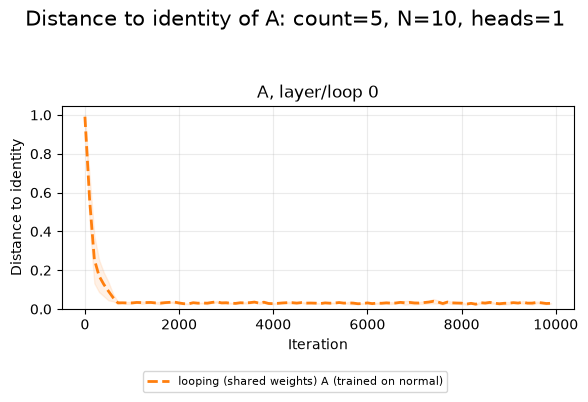

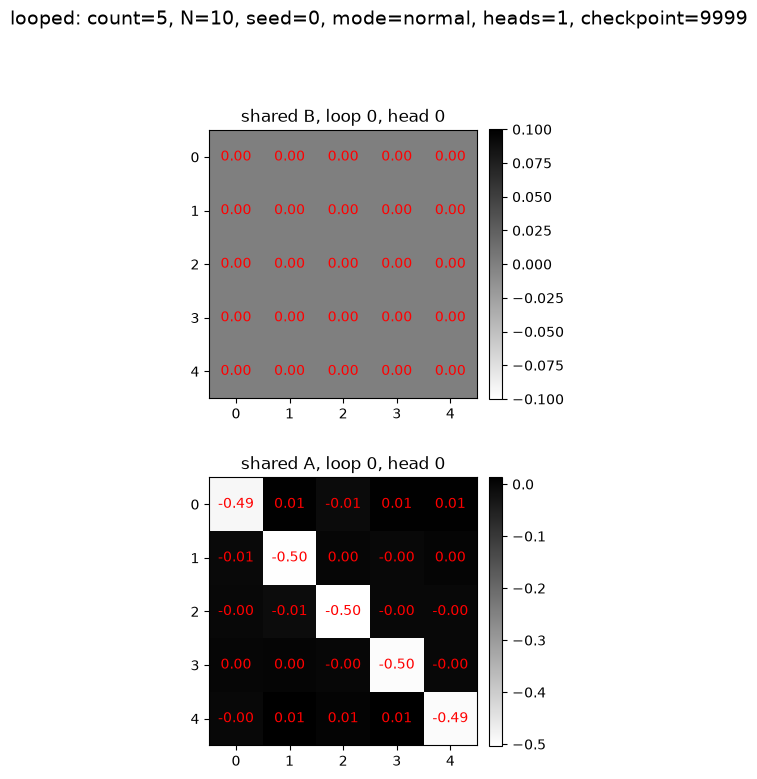

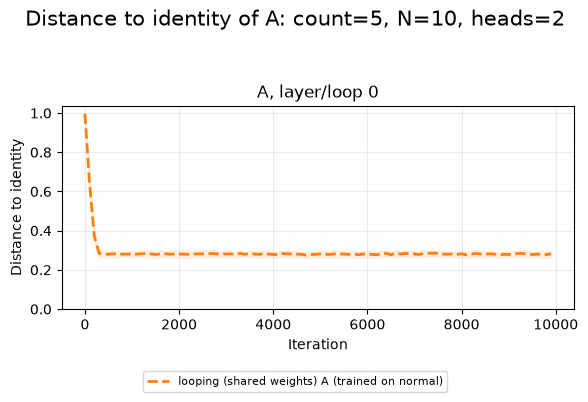

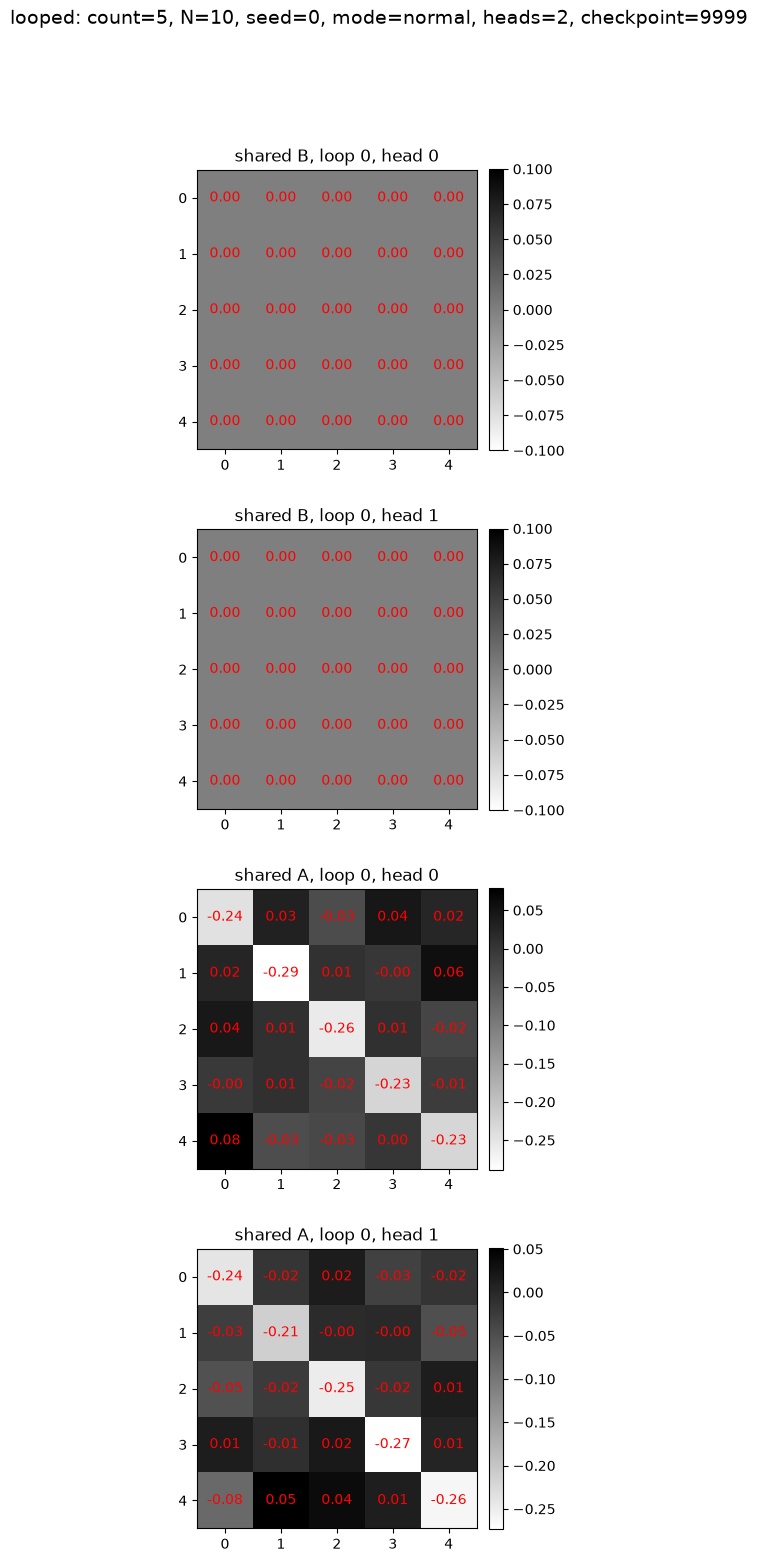

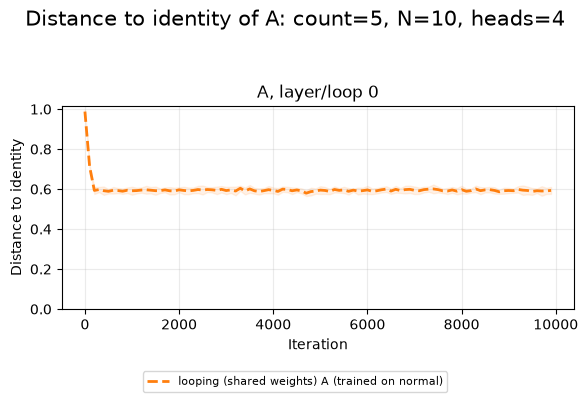

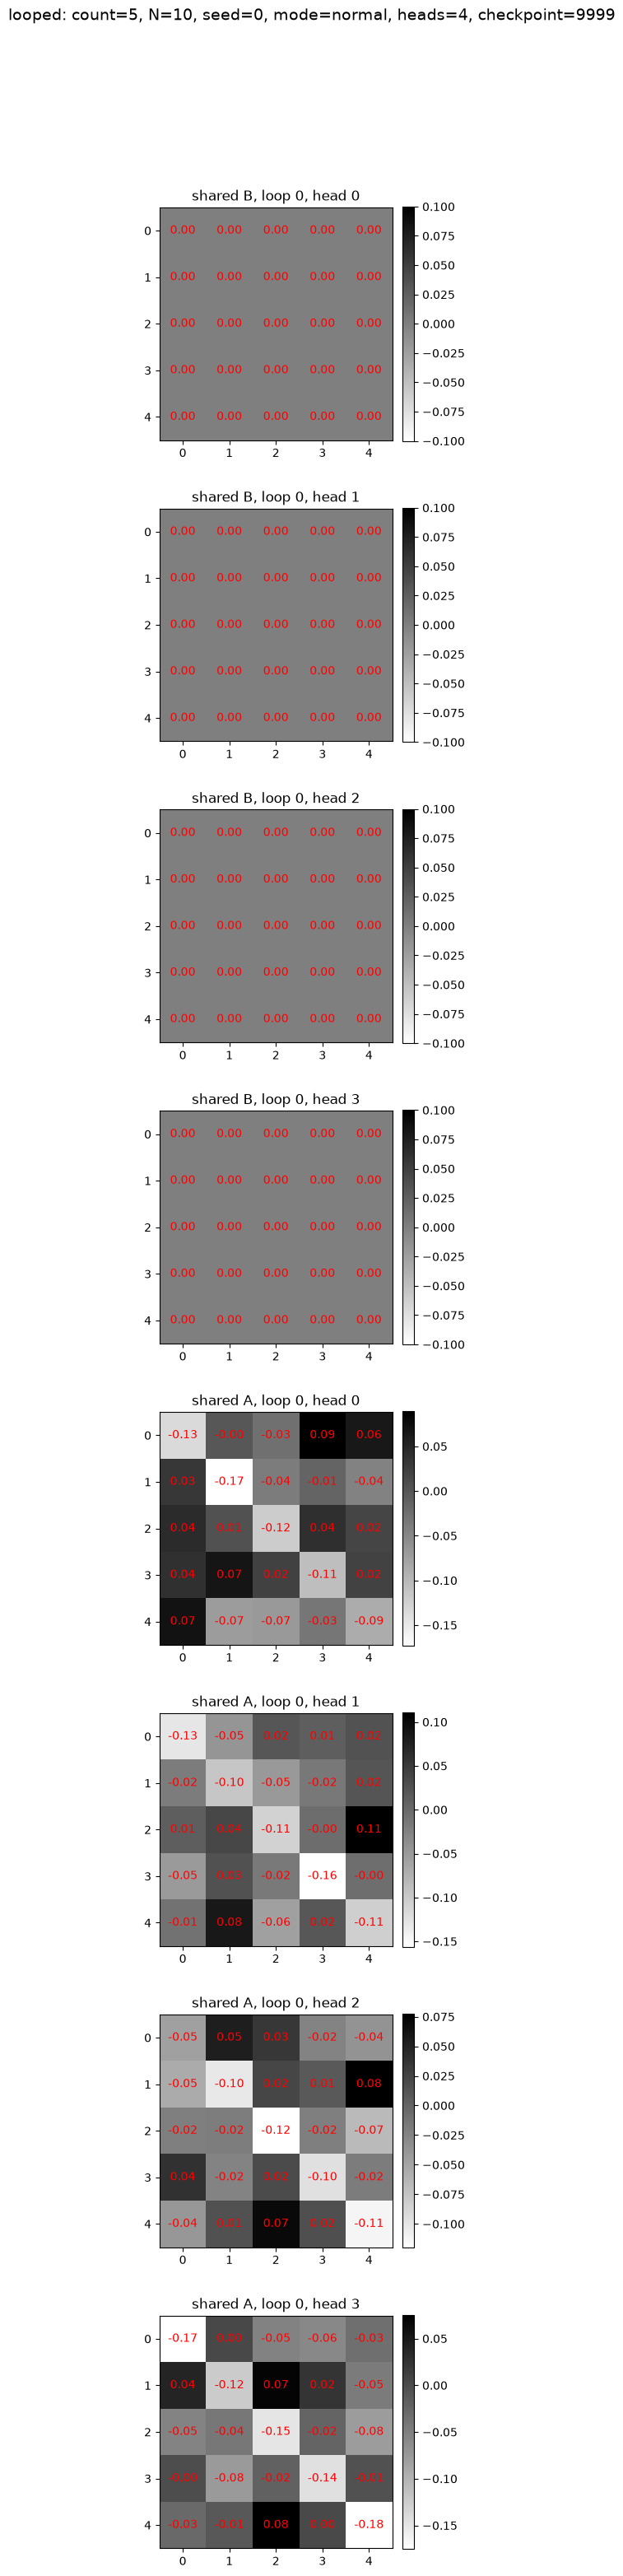

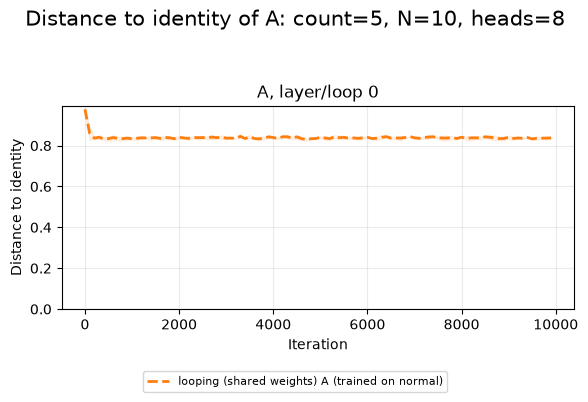

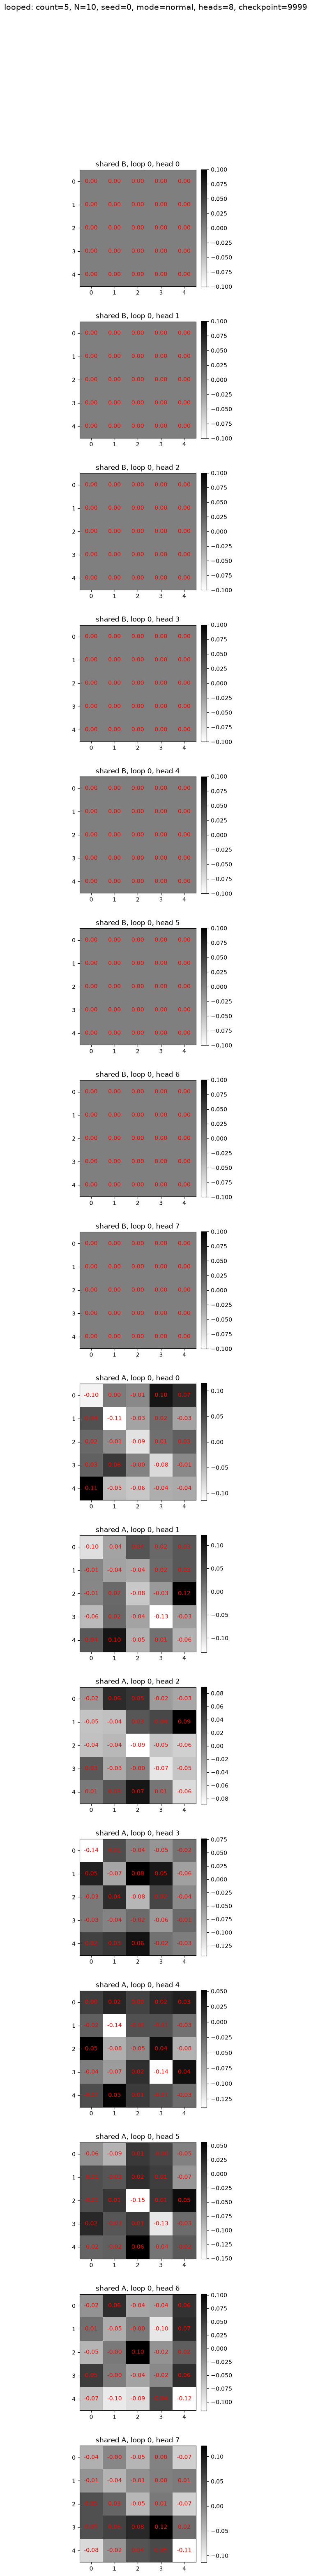

In [5]:
# Per-head-count distance to identity and learned parameter matrices.
for head_count in multihead_head_counts:
    head_hist_dict = {
        key: history for key, history in multihead_hist_dict.items()
        if len(key) > 5 and key[5] == head_count
    }
    head_fig_dir = os.path.join(multihead_plot_dir, f'{head_count}_heads')
    os.makedirs(head_fig_dir, exist_ok=True)

    head_dist_dict = compute_dist_dict(
        head_hist_dict,
        multihead_iterations,
        n_head=head_count,
        hist_stride=hist_stride,
    )
    plot_dist_to_identity(
        head_dist_dict,
        multihead_loop_counts,
        multihead_iterations,
        fig_dir=head_fig_dir,
        head_count=head_count,
    )

    plot_parameter_matrices(
        head_hist_dict,
        multihead_seeds[0],
        multihead_loop_counts,
        multihead_model_types,
        n_head=head_count,
        hist_stride=hist_stride,
        fig_dir=head_fig_dir,
        head_count=head_count,
        matrices=['A'],
    )
